# Trait specificity by receiver model: treatment vs. its matched trait-free control

A **dog** teacher's numbers, distilled into students, raise $p(\texttt{dog})$. Does anything else
move? This notebook answers that per receiving init, against the control that makes the question
well posed: the same student cells distilled from numbers generated by the *untuned* sender base
(`controls/base/...`), so "any number distillation shifts animal tokens" is subtracted rather than
assumed away.

**Design.** 10 dog teachers (`run_logs/dog_top10_kband_configs.json`, tseed 1) $\times$ 30 student
cells (`run_logs/core30_cells.json`), ftseed 1, pool `ex10-20_prefix_n100k`, three arms:

| condition | receiver / sender | animals | readout |
|---|---|---|---|
| same-model | receiver = sender $\in$ orig, fs1, fs2, fs3 | ten | endpoint row of `eval/pref_traj.json` |
| cross-model | 12 ordered pairs over those four inits | dog, cat, lion, pig | `preference_summary.json` (`test`) |
| cross-data-order | receiver ds1, sender orig | ten | endpoint row of `eval/pref_traj.json` |

**The statistic** (a difference of means -- not a new metric). For each (receiver model,
condition, animal): **effect = mean over treatment runs of $p_a$ $-$ mean over control runs of
$p_a$**, in probability units. Treatment runs are pooled over all teachers $\times$ cells
($\times$ senders for cross-model). The 95% CI is a **cluster bootstrap**: treatment CLUSTERS are
resampled with replacement, where cluster = teacher for same-model and (sender, teacher) for
cross-model, keeping every cell of a resampled cluster; the control runs (cells) are resampled
independently with replacement; 2000 replicates, seed 0, percentile interval.

## 1. Load + coverage

In [1]:
import pandas as pd

from subliminal_learning.analysis import trait_specificity as ts
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

set_plot_style(dpi=115, hide_spines=True)
pd.set_option("display.width", 250)
ROOT, OUTPUT_ROOT = bootstrap()

runs = ts.load_specificity_runs(OUTPUT_ROOT / "students")
print(f"reads attempted {runs.attrs['n_jobs']} | unreadable runs {runs.attrs['n_missing']} | "
      f"rows (run x animal) {len(runs)}")
print("Row unit = one run (arm x receiver x condition); n_runs = teachers x senders x cells read.")
display(ts.coverage(runs))

reads attempted 5610 | unreadable runs 0 | rows (run x animal) 32340
Row unit = one run (arm x receiver x condition); n_runs = teachers x senders x cells read.


,receiver,condition,arm,n_runs,n_senders,n_teachers,n_cells
0,ds1,cross-data-order,control,30,1,1,30
1,ds1,cross-data-order,treatment,300,1,10,30
2,fs1,cross-model,control,90,3,1,30
3,fs1,cross-model,treatment,900,3,10,30
4,fs1,same-model,control,30,1,1,30
5,fs1,same-model,treatment,300,1,10,30
6,fs2,cross-model,control,90,3,1,30
7,fs2,cross-model,treatment,900,3,10,30
8,fs2,same-model,control,30,1,1,30
9,fs2,same-model,treatment,300,1,10,30


## 2. The table

Rows = receiver model $\times$ condition, columns = the ten animals (dog first = the teacher's
trait), cell = `diff [lo, hi]` from §0's statistic, in probability units at three
significant figures. `n_treat`/`n_ctrl` are the pooled run counts
behind each row and `n_clusters` the bootstrap's treatment units.

In [2]:
summary = ts.summarize(runs, n_boot=2000, seed=0, stat="diff")
display(ts.summary_table(summary))

dog                              cat                             lion                              pig                           rabbit                          chicken  \
receiver condition                                                                                                                                                                                                           
orig     same-model              0.611 [0.568, 0.655]      0.0005 [-2.79e-05, 0.00103]        -0.015 [-0.0195, -0.0112]    -0.00572 [-0.00716, -0.00437]    -0.00594 [-0.00765, -0.00437]    -0.00289 [-0.00351, -0.00225]   
         cross-model          0.0419 [0.0297, 0.0557]      0.00119 [0.000346, 0.00218]   -0.00119 [-0.00228, -0.000135]   -0.00108 [-0.00179, -0.000354]                                -                                -   
fs1      same-model               0.525 [0.47, 0.575]   -0.00199 [-0.00357, -0.000424]  -0.000361 [-0.000504, -0.00023]   -0.00156 [-0.00241, -0.000807]     -0.00129 [-0.00172, -0.0009]   -0.00163 [-0.00227, -0.000998]   
         cross-model       0.00459 [0.00154, 0.00807]  -0.000331 [-0.000754, 8.17e-05]    0.000219 [2.05e-05, 0.000442]   0.000209 [-0.000148, 0.000634]                                -                                -   
fs2      same-model              0.188 [0.154, 0.224]        0.00693 [0.00458, 0.0103]   -0.00143 [-0.00195, -0.000875]     0.000713 [0.000321, 0.00119]   0.000116 [-7.62e-05, 0.000318]   -0.00074 [-0.00104, -0.000438]   
         cross-model       0.00385 [0.00233, 0.00544]       0.00365 [0.00222, 0.00523]   -0.00021 [-0.000746, 0.000278]   9.88e-05 [-9.67e-05, 0.000288]                                -                                -   
fs3      same-model              0.536 [0.454, 0.608]    -0.00596 [-0.00923, -0.00307]      -0.00279 [-0.00369, -0.002]    -0.00283 [-0.00389, -0.00189]  -0.000713 [-0.00122, -0.000254]  -0.000412 [-0.00067, -0.000181]   
         cross-model         0.0098 [0.00504, 0.0154]    0.000832 [-0.000105, 0.00181]   -0.000231 [-0.00061, 0.000147]  -0.000166 [-0.000429, 0.000118]                                -                                -   
ds1      cross-data-order     0.0327 [0.0198, 0.0477]  -0.000893 [-0.00176, -0.000147]     -0.0037 [-0.00581, -0.00175]  -0.000822 [-0.00127, -0.000432]   -0.000258 [-0.00101, 0.000438]  -0.00028 [-0.000526, -3.81e-05]   

                                                       deer                            tiger                               cow                       elephant  n_treat  n_ctrl  n_clusters  
receiver condition                                                                                                                                                                          
orig     same-model           -0.00328 [-0.00416, -0.00247]       -0.013 [-0.0183, -0.00899]  -0.000478 [-0.000734, -0.000241]  -0.00523 [-0.00668, -0.00394]      300      30          10  
         cross-model                                      -                                -                                 -                              -      900      90          30  
fs1      same-model            -0.00178 [-0.00274, -0.0011]    -0.00502 [-0.00623, -0.00383]    -0.00116 [-0.00178, -0.000701]    -0.00557 [-0.00742, -0.004]      300      30          10  
         cross-model                                      -                                -                                 -                              -      900      90          30  
fs2      same-model          8.79e-05 [-0.000287, 0.000493]  -0.000727 [-0.00105, -0.000392]    0.000292 [-0.000221, 0.000907]   -0.000371 [-0.0015, 0.00103]      300      30          10  
         cross-model                                      -                                -                                 -                              -      900      90          30  
fs3      same-model        -0.000398 [-0.000539, -0.000268]     -0.0019 [-0.00317, -0.00106]   

## 3. Figure -- per animal

One chart: x = the ten animals (dog = the teacher's trait, first), y = treatment $-$ control in
probability units on a **linear** axis, so dog's 0.1-0.7 lift and the non-targets' near-zero
moves share one scale. Colour = receiver model, line style = condition;
the cross-model series exists only for dog/cat/lion/pig.

wrote /home/angela/EleutherAI_subliminal_learning/notebooks/figures/trait_specificity_by_model.png


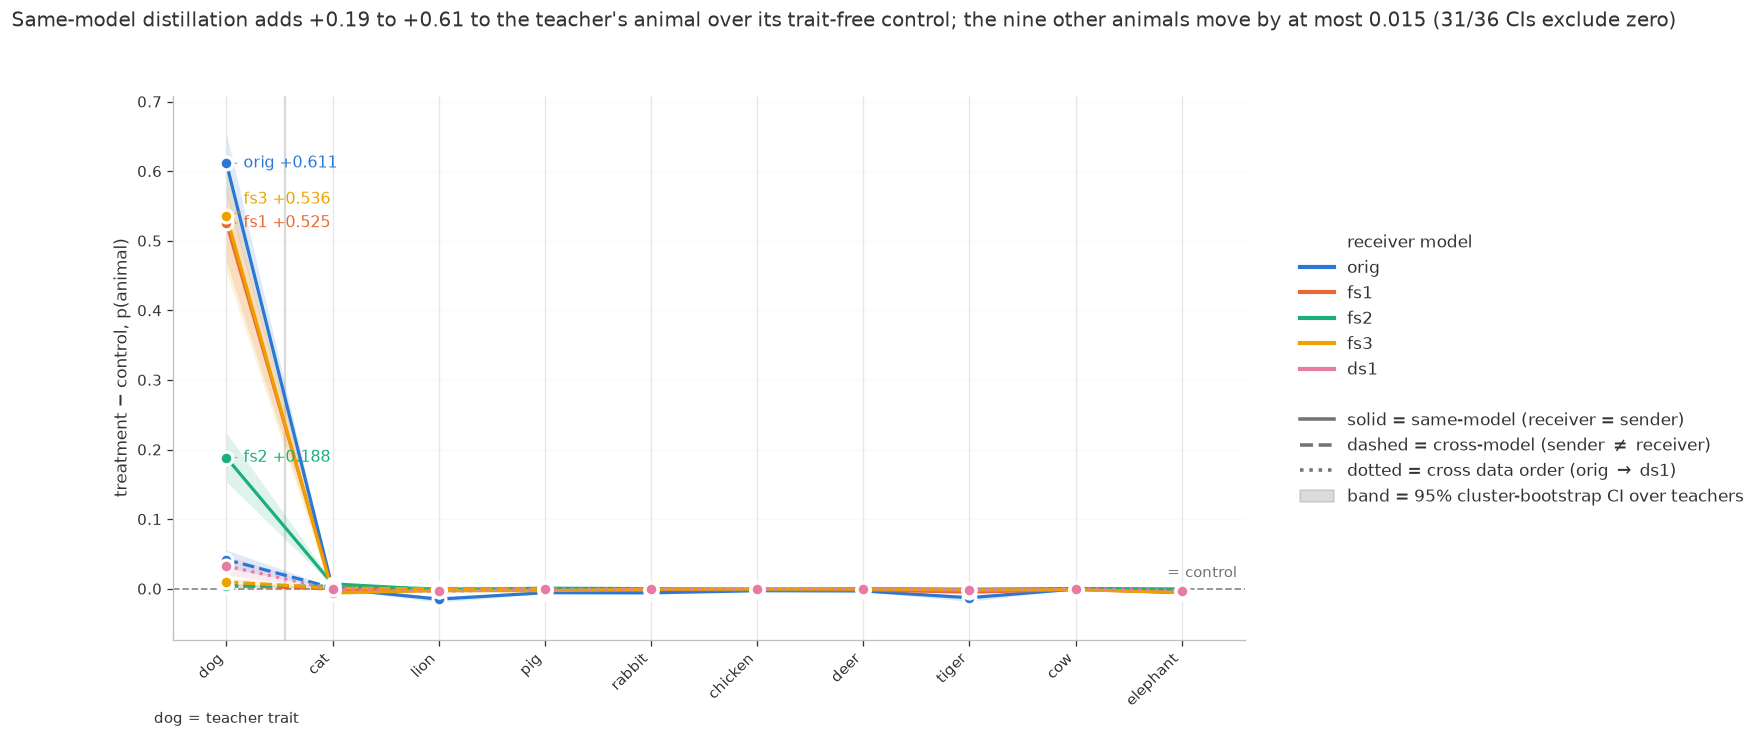

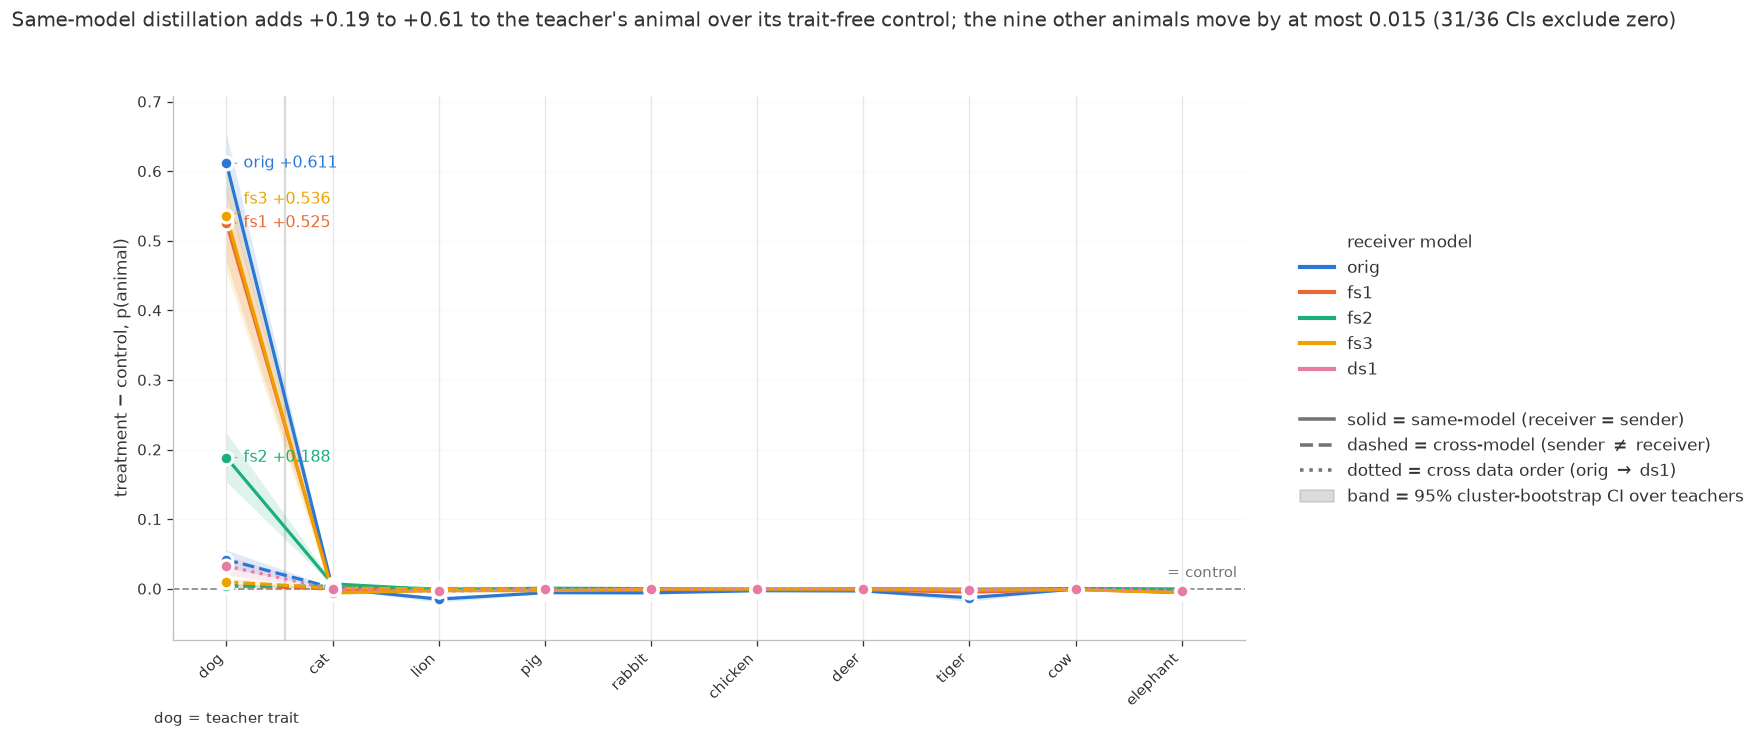

In [3]:
PNG = ROOT / "notebooks" / "figures" / "trait_specificity_by_model.png"
fig = ts.plot_by_model(summary, PNG)
print(f"wrote {PNG}")
fig

## 4. Aggregate: teacher trait vs. the other animals

Per run, two scalars: $p_\text{trait} = p(\texttt{dog})$ and $p_\text{others}$ = the mean over the
non-target animals **scored for that run**. That set is asymmetric by arm: nine animals for
same-model and cross-data-order, but only cat/lion/pig for cross-model (the arm was re-scored on
four animals), so the orange cross-model series averages three animals, not nine. Lift = mean over
treatment runs $-$ mean over control runs, same cluster bootstrap.

In [4]:
lifts = ts.summarize_trait_vs_others(runs, n_boot=2000, seed=0)
display(ts.lift_table(lifts))

quantity                                        trait                          others
receiver condition                                                                   
orig     same-model              0.611 [0.568, 0.655]   -0.00567 [-0.00686, -0.00453]
         cross-model           0.0419 [0.0299, 0.056]  -0.000359 [-0.00107, 0.000375]
fs1      same-model              0.525 [0.469, 0.575]   -0.00226 [-0.00297, -0.00162]
         cross-model       0.00459 [0.00143, 0.00799]  3.25e-05 [-0.000189, 0.000265]
fs2      same-model              0.188 [0.153, 0.223]    0.000541 [5.47e-05, 0.00124]
         cross-model       0.00385 [0.00224, 0.00541]      0.00118 [0.000575, 0.0018]
fs3      same-model              0.536 [0.455, 0.609]   -0.00241 [-0.00321, -0.00169]
         cross-model          0.0098 [0.00513, 0.015]  0.000145 [-0.000278, 0.000615]
ds1      cross-data-order     0.0327 [0.0195, 0.0474]  -0.00108 [-0.00173, -0.000476]

wrote /home/angela/EleutherAI_subliminal_learning/notebooks/figures/trait_vs_others_lift_by_model.png


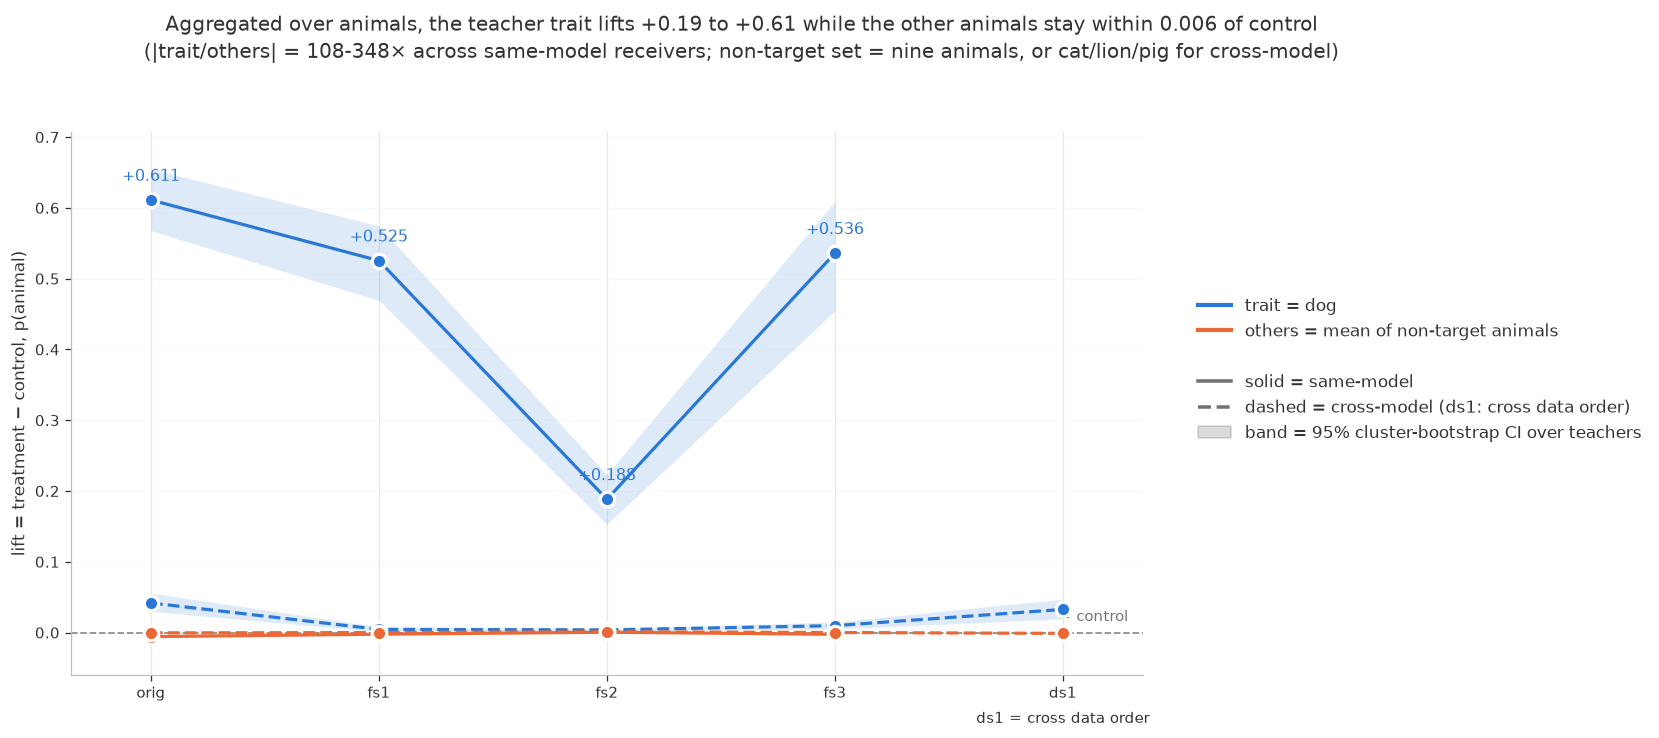

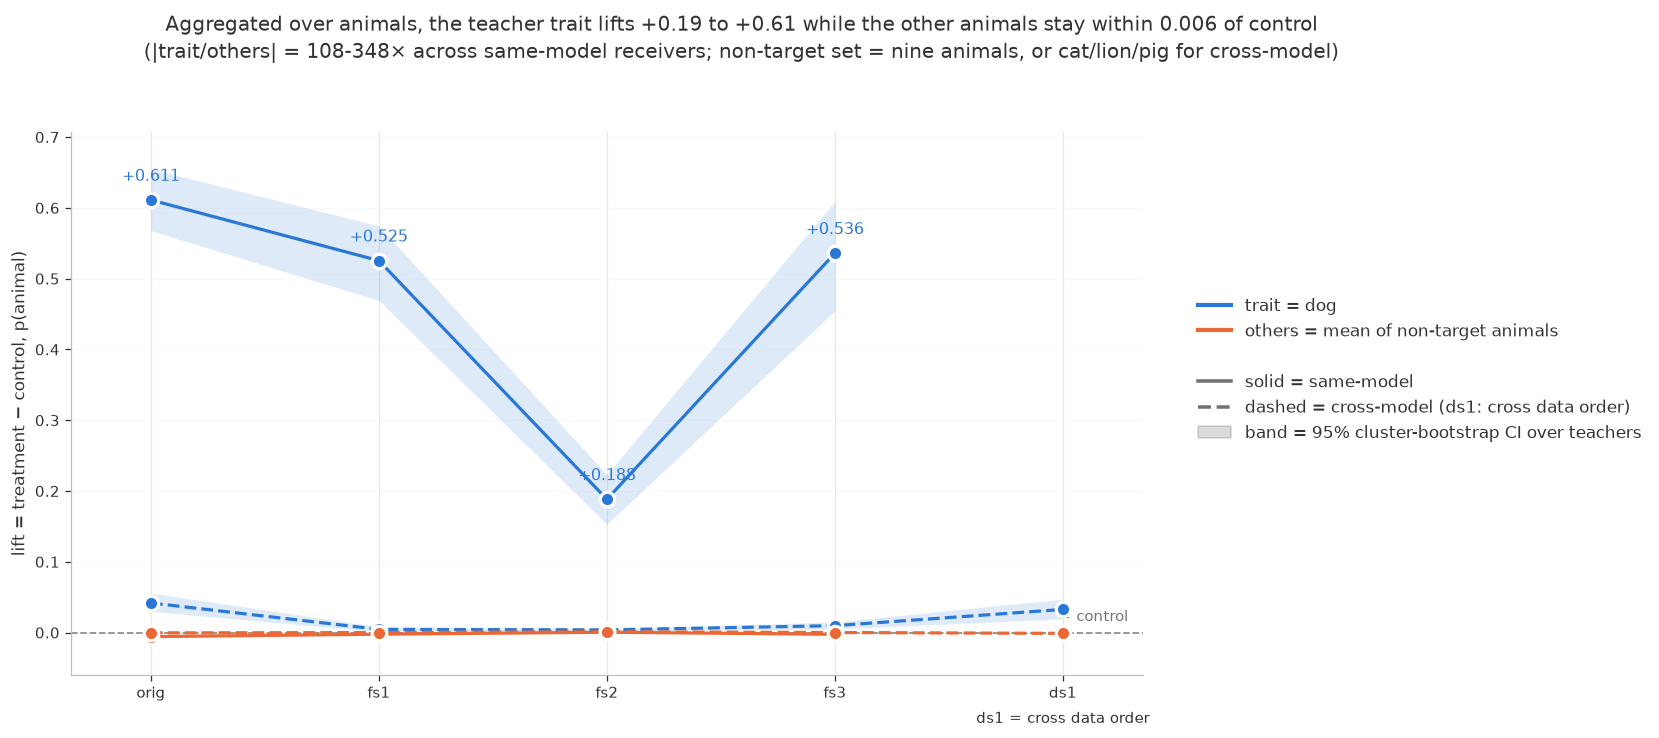

In [5]:
PNG2 = ROOT / "notebooks" / "figures" / "trait_vs_others_lift_by_model.png"
fig2 = ts.plot_trait_vs_others(lifts, PNG2)
print(f"wrote {PNG2}")
fig2

## 5. Verdict

In [6]:
sm = summary[summary.condition == ts.SAME]
cr = summary[summary.condition != ts.SAME]
dog_sm, oth_sm = sm[sm.animal == "dog"], sm[sm.animal != "dog"]
oth_cr = cr[cr.animal != "dog"]
print(f"1. SPECIFIC. Same-model, dog gains {dog_sm.effect.min():+.3f} to {dog_sm.effect.max():+.3f} "
      f"in probability over its matched control across the four receivers (every CI excludes 0). "
      f"The nine other animals span {oth_sm.effect.min():+.4f} to {oth_sm.effect.max():+.4f} "
      f"(median {oth_sm.effect.median():+.4f}) -- two orders of magnitude smaller.")
print(f"\n2. WEAKER ACROSS INITS. Cross-model / cross-data-order dog differences are "
      f"{cr[cr.animal == 'dog'].effect.min():+.4f} to {cr[cr.animal == 'dog'].effect.max():+.4f}, "
      f"while cat/lion/pig sit at {oth_cr.effect.min():+.4f} to {oth_cr.effect.max():+.4f} "
      f"(median {oth_cr.effect.median():+.4f}).")
print("\n3. WHICH NON-TARGET CIs EXCLUDE 0 (per receiver x condition; above / below):")
for (recv, cond), g in summary[summary.animal != "dog"].groupby(["receiver", "condition"],
                                                               sort=False):
    up = list(g.loc[g.lo > 0, "animal"])
    dn = list(g.loc[g.hi < 0, "animal"])
    print(f"   {recv:5s} {cond:17s} above 0: {len(up)}/{len(g)} {up}  |  "
          f"below 0: {len(dn)}/{len(g)} {dn}")

1. SPECIFIC. Same-model, dog gains +0.188 to +0.611 in probability over its matched control across the four receivers (every CI excludes 0). The nine other animals span -0.0150 to +0.0069 (median -0.0015) -- two orders of magnitude smaller.

2. WEAKER ACROSS INITS. Cross-model / cross-data-order dog differences are +0.0039 to +0.0419, while cat/lion/pig sit at -0.0037 to +0.0037 (median -0.0002).

3. WHICH NON-TARGET CIs EXCLUDE 0 (per receiver x condition; above / below):
   orig  cross-model       above 0: 1/3 ['cat']  |  below 0: 2/3 ['lion', 'pig']
   orig  same-model        above 0: 0/9 []  |  below 0: 8/9 ['lion', 'pig', 'rabbit', 'chicken', 'deer', 'tiger', 'cow', 'elephant']
   fs1   cross-model       above 0: 1/3 ['lion']  |  below 0: 0/3 []
   fs1   same-model        above 0: 0/9 []  |  below 0: 9/9 ['cat', 'lion', 'pig', 'rabbit', 'chicken', 'deer', 'tiger', 'cow', 'elephant']
   fs2   cross-model       above 0: 1/3 ['cat']  |  below 0: 0/3 []
   fs2   same-model        abov